In [2]:
import sys, os
print("python:", sys.executable)
print("cwd:   ", os.getcwd())
import streamsculptor
print("path:  ", list(streamsculptor.__path__))
print("file:  ", streamsculptor.__file__)

python: /opt/anaconda3/envs/streams/bin/python3.12
cwd:    /Users/mariamkhan
path:   ['/opt/anaconda3/envs/streams/lib/python3.12/site-packages/streamsculptor']
file:   None


In [3]:
!ls -la /opt/anaconda3/envs/streams/lib/python3.12/site-packages/streamsculptor

total 0
drwxr-xr-x    3 mariamkhan  staff    96 29 Oct 11:47 __pycache__
-rw-r--r--    1 mariamkhan  staff     0 29 Oct 11:47 _init_.py
drwxr-xr-x    4 mariamkhan  staff   128 29 Oct 11:47 .
drwxr-xr-x  281 mariamkhan  staff  8992 29 Oct 11:47 ..


In [4]:
!rm -rf /opt/anaconda3/envs/streams/lib/python3.12/site-packages/streamsculptor

In [2]:
%pip install -e ~/code/streamsculptor

Obtaining file:///Users/mariamkhan/code/streamsculptor
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Using cached numpy-2.1.3-cp312-cp312-macosx_14_0_arm64.whl.metadata (62 kB)
Using cached numpy-2.1.3-cp312-cp312-macosx_14_0_arm64.whl (5.1 MB)
  Building editable for streamsculptor (pyproject.toml) ... done
  Created wheel for streamsculptor: filename=streamsculptor-0.1.0-0.editable-py3-none-any.whl size=5612 sha256=4fb4d490a2a881792eff83d5c973ae70fded217c68b354a43a70ac246ae200a0
  Stored in directory: /private/var/folders/h3/fz1rp8057wj6r12l46wrjwbr0000gn/T/pip-ephem-wheel-cache-iai9qtmp/wheels/8c/4e/64/e427987f0ed76cefcd426d3ca1ec485012bed87ee716e9b4f7
Successfully built streamsculptor
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled nu

In [3]:
!pip show streamsculptor

Name: streamsculptor
Version: 0.1.0
Summary: JAX-based library for modeling stellar streams in galactic potentials
Home-page: https://github.com/jnibauer/streamsculptor
Author: 
Author-email: Jacob Nibauer <jn5830@princeton.edu>
License: MIT
Location: /opt/anaconda3/envs/streams/lib/python3.12/site-packages
Editable project location: /Users/mariamkhan/code/streamsculptor
Requires: astropy, diffrax, equinox, interpax, jax, jaxopt, numpy, optax, quadax, tqdm
Required-by: 


In [1]:
import streamsculptor
print(streamsculptor.__file__)

from streamsculptor import potential

/Users/mariamkhan/code/streamsculptor/streamsculptor/__init__.py


In [16]:
#%pip install gala astropy jax diffrax matplotlib numpy streamsculptor
import sys
print(sys.executable)

/opt/anaconda3/envs/streams/bin/python3.12


In [13]:
import sys
print(sys.executable)   # should contain /envs/streams/
import streamsculptor
print(streamsculptor.__file__)
from streamsculptor import potential
print(potential.GalaMilkyWayPotential)

/opt/anaconda3/envs/streams/bin/python3.12
/Users/mariamkhan/code/streamsculptor/streamsculptor/__init__.py
<class 'streamsculptor.potential.GalaMilkyWayPotential'>


In [3]:
from gala.units import UnitSystem
from astropy import units as u
usys = UnitSystem(u.kpc, u.Myr, u.Msun, u.radian)
import jax.numpy as jnp

import diffrax


import matplotlib.pyplot as plt
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)

import streamsculptor
from streamsculptor import potential
 


Initial condition = [ -7.23544156  -7.96290672 -10.81798608   0.19179774  -0.2035431
  -0.01775124]


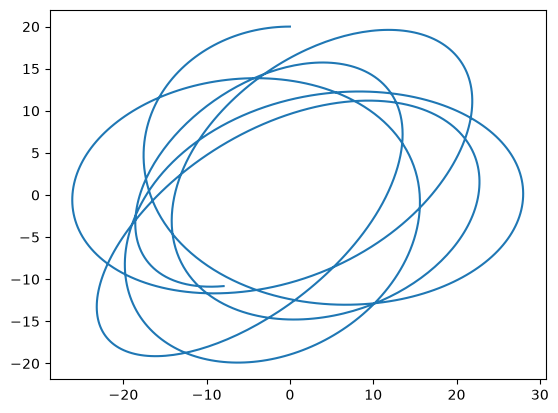

In [4]:
## Define a potential
pot_MW = potential.GalaMilkyWayPotential()

## Define a stream progenitor (observed today)
w_today = jnp.array([20.0,0.0,20,.0,.15,.0]) # position units: kpc, velocity units: kpc/Myr

## Stream age
t_age = 3_500 # Myr

## Times to backwards integrate through
ts_back = jnp.linspace(0,-t_age, 1000) #save 1000 points
init_cond = pot_MW.integrate_orbit(w0=w_today, ts=ts_back,t0=0.0, t1=-t_age,)

## Initial condition at t1 = -t_age
IC = init_cond.ys[-1]
print('Initial condition = ' + str(IC))
plt.plot(init_cond.ys[:,1], init_cond.ys[:,2]);